# Classes for engineering components: materials, stress–strain and a bar in tension

*Python for Engineers: Case Studies from Calculator to Simulation* · Notebook 10 · Yanwei Wang

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/python-for-engineers-case-studies/blob/main/notebooks/10_Classes_for_Engineering_Components.ipynb)

An engineer choosing a material for a tie bar keeps several facts about each candidate together: its stiffness, its strength, its density, and how it behaves when loaded past its limit. A program needs to do the same. So far we have stored data in variables, lists and dictionaries and kept the calculations in separate functions. As programs grow, that separation becomes a source of mistakes.

A **class** bundles data and the functions that act on that data into one new type of object. In this notebook you will:

1. see why a dictionary plus separate functions becomes fragile;
2. write a `Material` class with **attributes** (data) and **methods** (functions attached to the object);
3. use **inheritance** to define materials that behave differently past their limit: a strain-hardening metal and a brittle ceramic;
4. build a `Bar` component that **has** a material, and use it to choose the lightest bar for a load.

**How to study:** predict each output before running a cell. The notebook uses plain Python, plus Matplotlib for one plot.

<!-- pfe-study-guide -->
## Study guide

| | |
|---|---|
| **Status** | Core · Part 4, Objects |
| **Time** | about 45 min (about 75 min with the practice) |
| **Before this** | Notebooks 01–03 (functions, lists, dictionaries) and notebook 08 (`assert`, `raise`). |
| **Essential** | All sections. |
| **Optional on a first reading** | — |
| **Next** | 11, Factory queues: a simulation built from objects. |

**You have understood this notebook if you can, without looking back:**

1. Write a class with `__init__`, attributes and methods, and explain what `self` is.
2. Put input checks in `__init__`, and explain why that is better than checking later.
3. Write a subclass that overrides one method and reuses its parent through `super()`.
4. Explain polymorphism using the stress–strain loop in Section 5.
5. Decide between inheritance ("is a") and composition ("has a") for a new component.

**Not expected of you:** Special methods beyond `__init__` and `__repr__`, class attributes or `@property`.

*The comment on every code line is a reading aid. In your own programs, comment the reasons and the non-obvious steps.*

## 1. The problem: data in one place, rules in another

Here is a material stored as a dictionary, with a separate function for its stress at a given strain. A **linear-elastic, perfectly plastic** material follows Hooke's law, $\sigma = E\varepsilon$, until the stress reaches the yield strength $\sigma_y$. It then carries $\sigma_y$ however far it is stretched.

In [1]:
# One gigapascal and one megapascal, in pascals: we store everything in SI units.
GPA, MPA = 1e9, 1e6
# Structural steel as a dictionary of properties.
steel_dict = {"name": "structural steel", "E": 200 * GPA, "yield_strength": 250 * MPA, "density": 7850.0}


# Stress in Pa at a given strain, for an elastic, perfectly plastic material.
def stress_from_dict(material, strain):
    # Hooke's law, capped at the yield strength.
    return min(material["E"] * strain, material["yield_strength"])


# Stress at 0.05 % strain (still elastic) and at 1 % strain (yielded), in MPa.
print(stress_from_dict(steel_dict, 0.0005) / MPA, "MPa,", stress_from_dict(steel_dict, 0.01) / MPA, "MPa")

100.0 MPa, 250.0 MPa


This works, but it is fragile:

- A typo in a key, such as `"yeild_strength"`, is only discovered when a calculation fails, possibly far from where the typo was made.
- Nothing stops you passing a pipe's dictionary to a material function.
- A ceramic breaks instead of yielding. Its stress rule needs a different function, and every caller must remember which function goes with which dictionary.

A class solves all three problems: the data and its rules travel together.

## 2. Defining a class

```python
class Material:                       # the new type is called Material
    def __init__(self, name, E, ...): # runs when a Material is created
        self.name = name              # store data on the object
    def stress(self, strain):         # a method: a function that belongs to the object
        ...
```

- `class Material:` defines a **blueprint**. Each object made from it is an **instance**.
- `__init__` (two underscores on each side) runs automatically when an instance is created. It stores the data as **attributes**, written `self.name`, `self.E` and so on.
- `self` is the instance itself. Python passes it automatically: `steel.stress(0.01)` calls `stress` with `self = steel`.

In [2]:
# A blueprint for linear-elastic, perfectly plastic materials.
class Material:
    # The docstring describes the class and its units.
    """An elastic, perfectly plastic material. All values in SI units (Pa, kg/m³)."""

    # Runs when a new Material is created.
    def __init__(self, name, E, yield_strength, density):
        # Refuse impossible values at once, before they cause trouble later.
        if E <= 0 or yield_strength <= 0 or density <= 0:
            # A clear message naming the material.
            raise ValueError(f"{name}: E, yield strength and density must all be positive")
        # Store each property as an attribute of this object.
        self.name = name
        # Young's modulus in Pa.
        self.E = E
        # Yield strength in Pa.
        self.yield_strength = yield_strength
        # Density in kg/m³.
        self.density = density

    # The strain at which yielding starts.
    def yield_strain(self):
        # From Hooke's law: ε_y = σ_y / E.
        return self.yield_strength / self.E

    # Stress in Pa at a given tensile strain.
    def stress(self, strain):
        # Elastic up to the yield strain ...
        if strain <= self.yield_strain():
            # ... Hooke's law ...
            return self.E * strain
        # ... then constant at the yield strength.
        return self.yield_strength

    # Stiffness per unit mass, in MN·m/kg (a figure of merit for light, stiff parts).
    def specific_stiffness(self):
        # E / ρ, converted from J/kg to MJ/kg (numerically MN·m/kg).
        return self.E / self.density / 1e6

    # How the object is shown by print() and in lists.
    def __repr__(self):
        # Name plus the two key properties, in everyday units.
        return f"{type(self).__name__}({self.name!r}, E={self.E / GPA:.0f} GPa, σy={self.yield_strength / MPA:.0f} MPa)"

Creating an instance looks like calling a function. The arguments go to `__init__`; `self` is supplied by Python.

In [3]:
# Create two instances of Material.
steel = Material("structural steel", E=200 * GPA, yield_strength=250 * MPA, density=7850.0)
# Aluminium alloy 6061-T6.
aluminium = Material("aluminium 6061-T6", E=69 * GPA, yield_strength=276 * MPA, density=2700.0)
# print uses __repr__.
print(steel)
# Attributes are read with a dot.
print("aluminium density:", aluminium.density, "kg/m³")
# Methods are called with a dot and parentheses; Python passes the object as self.
print(f"aluminium yields at a strain of {aluminium.yield_strain():.5f} ({aluminium.yield_strain() * 100:.2f} %)")
# Same calculations as with the dictionary, now as methods.
print(steel.stress(0.0005) / MPA, "MPa,", steel.stress(0.01) / MPA, "MPa")
# The class must agree with the dictionary version above.
assert steel.stress(0.01) == stress_from_dict(steel_dict, 0.01)

Material('structural steel', E=200 GPa, σy=250 MPa)
aluminium density: 2700.0 kg/m³
aluminium yields at a strain of 0.00400 (0.40 %)
100.0 MPa, 250.0 MPa


A misspelt attribute now fails at the line where it is misspelt, with an error message that names the class. Invalid data is refused when the object is created, not later.

In [4]:
# Misspell an attribute name.
try:
    # There is no attribute called yeild_strength.
    print(steel.yeild_strength)
# Python names the object's type and the missing attribute.
except AttributeError as err:
    # Show the message.
    print("AttributeError:", err)
# Try to create a material with a negative modulus.
try:
    # A sign error in the input.
    Material("bad input", E=-70 * GPA, yield_strength=100 * MPA, density=2700.0)
# The check in __init__ refuses it.
except ValueError as err:
    # Show the message.
    print("ValueError:", err)

AttributeError: 'Material' object has no attribute 'yeild_strength'
ValueError: bad input: E, yield strength and density must all be positive


## 3. Many objects, one interface

Because every `Material` has the same methods, a list of materials can be processed with one loop. Sorting by a method works too: `sorted(items, key=f)` sorts by the value `f(item)`, and `Material.specific_stiffness` is exactly such a function.

**Predict** before running: which of the three metals is stiffest *per kilogram*?

In [5]:
# Titanium alloy Ti-6Al-4V.
titanium = Material("titanium Ti-6Al-4V", E=114 * GPA, yield_strength=880 * MPA, density=4430.0)
# High-density polyethylene, a common polymer.
hdpe = Material("HDPE", E=1.0 * GPA, yield_strength=25 * MPA, density=950.0)
# All four candidates in one list.
candidates = [steel, aluminium, titanium, hdpe]
# Sort from stiffest to least stiff per kilogram.
for m in sorted(candidates, key=Material.specific_stiffness, reverse=True):
    # One line per material.
    print(f"{m.name:22s} E/ρ = {m.specific_stiffness():5.1f} MN·m/kg")

titanium Ti-6Al-4V     E/ρ =  25.7 MN·m/kg
aluminium 6061-T6      E/ρ =  25.6 MN·m/kg
structural steel       E/ρ =  25.5 MN·m/kg
HDPE                   E/ρ =   1.1 MN·m/kg


Steel, aluminium and titanium have almost the same specific stiffness, about 25 MN·m/kg. A lighter metal is also less stiff, in nearly the same proportion. This is why aircraft designers choose metals for strength, fatigue or cost rather than for stiffness per kilogram.

## 4. Inheritance: materials that behave differently

Real materials do not all follow the elastic, perfectly plastic rule:

- Most metals **strain-harden**: after yielding, the stress keeps rising, roughly as $\sigma = \sigma_y + H(\varepsilon - \varepsilon_y)$ with a hardening modulus $H$ much smaller than $E$.
- A ceramic is **brittle**: it is elastic until it fractures, and then carries nothing.

Both are still materials, with a modulus, a strength and a density. **Inheritance** lets a new class reuse everything from an existing one and change only what differs. `class HardeningMetal(Material):` means "a HardeningMetal **is a** Material". The new class:

- **inherits** every method it does not redefine, such as `yield_strain` and `specific_stiffness`;
- **overrides** a method by defining one with the same name, here `stress`;
- calls the parent's version with `super()`, for example `super().__init__(...)` to reuse the parent's checks and attributes.

In [6]:
# A metal that strain-hardens linearly after yielding.
class HardeningMetal(Material):
    # The docstring states the extra property.
    """Elastic, then linear strain hardening with modulus H (Pa)."""

    # The parent's four properties, plus the hardening modulus.
    def __init__(self, name, E, yield_strength, density, H):
        # Let Material store and check the common properties.
        super().__init__(name, E, yield_strength, density)
        # The extra attribute only this class has.
        self.H = H

    # Override: stress keeps rising after yield.
    def stress(self, strain):
        # Below yield, the parent's elastic rule applies unchanged.
        if strain <= self.yield_strain():
            # Hooke's law, from Material.stress.
            return super().stress(strain)
        # Past yield: yield strength plus hardening.
        return self.yield_strength + self.H * (strain - self.yield_strain())


# A brittle material: elastic until it fractures.
class Ceramic(Material):
    # The docstring explains the meaning of "yield strength" here.
    """Linear elastic up to fracture; the strength is the fracture stress."""

    # Override: no plastic range, the material breaks.
    def stress(self, strain):
        # Below the fracture strain the ceramic is elastic ...
        if strain <= self.yield_strain():
            # ... Hooke's law ...
            return self.E * strain
        # ... beyond it the part is broken and carries no load.
        return 0.0

    # A method only ceramics have.
    def is_broken(self, strain):
        # True once the fracture strain has been passed.
        return strain > self.yield_strain()


# Steel again, now with strain hardening (H = 2 GPa).
steel_h = HardeningMetal("structural steel", E=200 * GPA, yield_strength=250 * MPA, density=7850.0, H=2 * GPA)
# Alumina, a technical ceramic; 300 MPa is a typical fracture strength in tension.
alumina = Ceramic("alumina", E=370 * GPA, yield_strength=300 * MPA, density=3950.0)
# Inherited method: works without being redefined.
print(f"{steel_h.name}: yield strain {steel_h.yield_strain():.5f}, E/ρ = {steel_h.specific_stiffness():.1f} MN·m/kg")
# Overridden method: stress at 1 % strain is above the yield strength now.
print(f"{steel_h.name}: stress at 1 % strain = {steel_h.stress(0.01) / MPA:.1f} MPa")
# The ceramic at 0.05 % strain and at 0.1 % strain.
print(f"alumina: {alumina.stress(0.0005) / MPA:.0f} MPa at 0.05 %; broken at 0.1 %? {alumina.is_broken(0.001)}")
# isinstance asks "is this object a ...?"; a subclass instance is also an instance of its parent.
print("steel_h is a Material:", isinstance(steel_h, Material), "; alumina is a HardeningMetal:", isinstance(alumina, HardeningMetal))

structural steel: yield strain 0.00125, E/ρ = 25.5 MN·m/kg
structural steel: stress at 1 % strain = 267.5 MPa
alumina: 185 MPa at 0.05 %; broken at 0.1 %? True
steel_h is a Material: True ; alumina is a HardeningMetal: False


**Checks against hand calculations.** At 1 % strain the hardening steel carries $250 + 2000\,(0.01 - 0.00125) = 267.5$ MPa. Alumina fractures at $300/370\,000 \approx 0.081$ % strain.

In [7]:
# The math module provides isclose for comparing floats.
import math
# Hardening steel at 1 % strain: 267.5 MPa.
assert math.isclose(steel_h.stress(0.01), 267.5 * MPA)
# Below yield, the hardening metal and the plain material agree exactly.
assert steel_h.stress(0.001) == steel.stress(0.001)
# Alumina's fracture strain is about 0.081 %.
assert math.isclose(alumina.yield_strain(), 300 / 370_000)
# Past fracture the ceramic carries nothing.
assert alumina.stress(0.002) == 0.0
# All checks passed.
print("hand-calculation checks passed")

hand-calculation checks passed


## 5. Polymorphism: one loop, different behaviour

The loop below calls `m.stress(strain)` on every material without knowing which class each one belongs to. Each object answers with its **own** version of `stress`. This is called **polymorphism**: the same method call works on objects of different classes. A new class, say for a polymer that softens, could be added later without changing this loop at all.

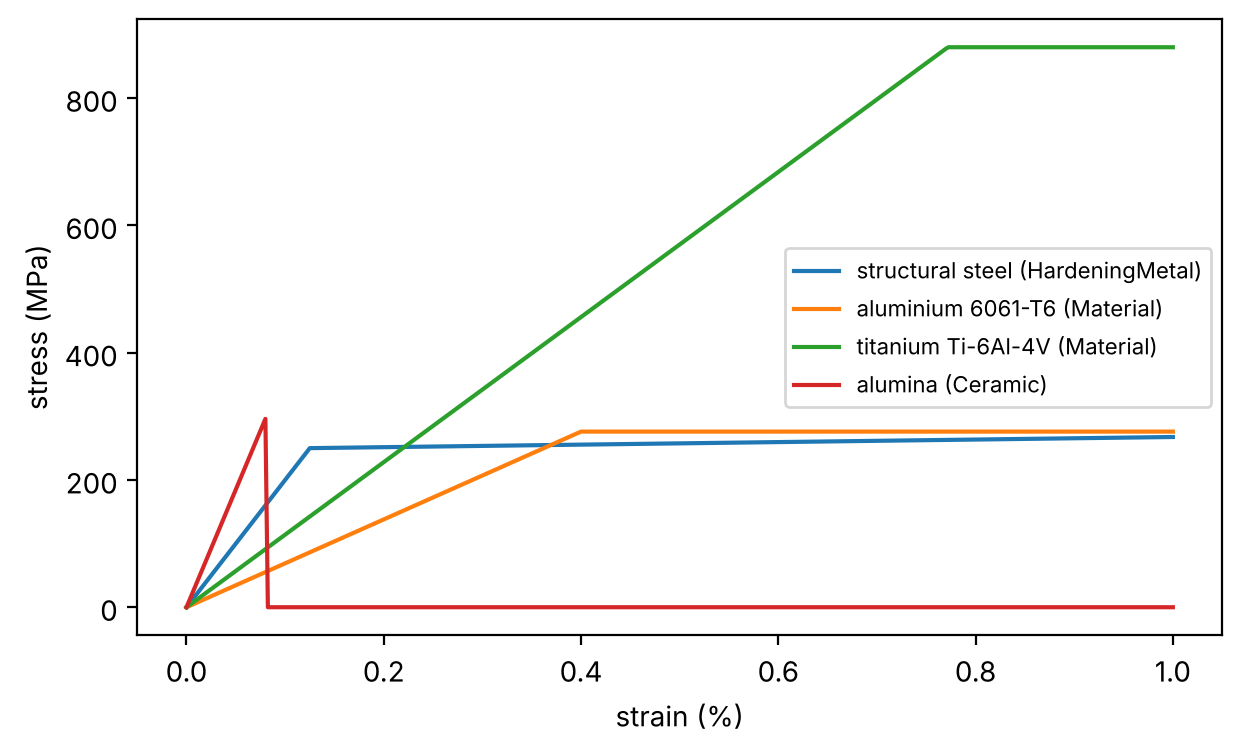

In [8]:
# Load Matplotlib's plotting interface.
import matplotlib.pyplot as plt
# Strains from 0 to 1 % in 401 small steps.
strains = [0.01 * i / 400 for i in range(401)]
# The materials to compare; three different classes.
curves = [steel_h, aluminium, titanium, alumina]
# A figure 7 inches wide and 4 inches tall.
plt.figure(figsize=(7, 4))
# One curve per material.
for m in curves:
    # Ask each object for its stress at every strain, converted to MPa.
    stresses = [m.stress(e) / MPA for e in strains]
    # Strain in percent on the x-axis; the label shows the class too.
    plt.plot([100 * e for e in strains], stresses, label=f"{m.name} ({type(m).__name__})")
# Axis labels with units.
plt.xlabel("strain (%)")
# The y-axis label.
plt.ylabel("stress (MPa)")
# Legend in the free space on the right.
plt.legend(loc="center right", fontsize=8)
# Display the figure.
plt.show()

## 6. Composition: a component that *has* a material

A tie bar is not a kind of material, so it should not inherit from `Material`. Instead it **has** a material, as one of its attributes. This is called **composition**. The rule of thumb:

- use inheritance when "B **is an** A" is true (a ceramic is a material);
- use composition when "B **has an** A" is true (a bar has a material).

The `Bar` class asks its material for properties and leaves the stress–strain behaviour to the material.

In [9]:
# A straight bar loaded in tension.
class Bar:
    # The docstring states the units.
    """A prismatic bar: length in m, cross-sectional area in m², made of a Material."""

    # A bar is defined by its material and its geometry.
    def __init__(self, material, length, area):
        # Composition: the bar stores a Material object as an attribute.
        self.material = material
        # Length in metres.
        self.length = length
        # Cross-sectional area in m².
        self.area = area

    # Mass in kilograms.
    def mass(self):
        # Density × volume.
        return self.material.density * self.area * self.length

    # The largest force the bar carries before yielding (or fracturing), in N.
    def limit_force(self):
        # Strength × area.
        return self.material.yield_strength * self.area

    # Safety factor against yield for an applied force in N.
    def safety_factor(self, force):
        # Limit force divided by applied force.
        return self.limit_force() / force

    # Elastic elongation in metres under a force in N.
    def elongation(self, force):
        # Refuse forces beyond the elastic range, where δ = FL/(EA) no longer holds.
        if force > self.limit_force():
            # Explain what went wrong.
            raise ValueError(f"{force:.0f} N exceeds the elastic limit {self.limit_force():.0f} N")
        # δ = F L / (E A).
        return force * self.length / (self.material.E * self.area)


# A 1 m aluminium bar with a 20 mm × 20 mm square section.
bar = Bar(aluminium, length=1.0, area=0.020 * 0.020)
# Its mass, limit force and behaviour under 50 kN.
print(f"mass {bar.mass():.2f} kg, limit force {bar.limit_force() / 1e3:.1f} kN")
# Safety factor and stretch under 50 kN.
print(f"under 50 kN: safety factor {bar.safety_factor(50e3):.2f}, elongation {bar.elongation(50e3) * 1e3:.2f} mm")
# Hand check: 50 000 × 1 / (69e9 × 4e-4) = 1.81 mm.
assert math.isclose(bar.elongation(50e3), 50e3 / (69e9 * 4e-4))

mass 1.08 kg, limit force 110.4 kN
under 50 kN: safety factor 2.21, elongation 1.81 mm


## 7. Using the classes: the lightest tie bar

**Design task:** a 1 m tie bar must carry 50 kN with a safety factor of 2 against yield (or fracture). Which material gives the lightest bar?

For each material, the required area is $A = 2F/\sigma_y$, and the mass follows from the `Bar` class. The loop needs no `if` for each class: every candidate answers the same questions.

In [10]:
# The design load in newtons.
force = 50e3
# The required safety factor.
required_sf = 2.0
# The candidates: three classes, one interface.
options = [steel_h, aluminium, titanium, alumina, hdpe]
# Bars sized for the load, one per material.
designs = []
# Size a bar in each material.
for m in options:
    # Area that gives exactly the required safety factor.
    area = required_sf * force / m.yield_strength
    # Build the bar object.
    designs.append(Bar(m, length=1.0, area=area))
# Table header.
print(f"{'material':22s} {'area (mm²)':>10s} {'mass (kg)':>9s} {'SF':>5s}")
# Lightest first: the key is each bar's mass method.
for b in sorted(designs, key=Bar.mass):
    # One table row.
    print(f"{b.material.name:22s} {b.area * 1e6:10.0f} {b.mass():9.2f} {b.safety_factor(force):5.2f}")
# Every design must meet the safety factor (to round-off).
assert all(math.isclose(b.safety_factor(force), required_sf) for b in designs)

material               area (mm²) mass (kg)    SF
titanium Ti-6Al-4V            114      0.50  2.00
aluminium 6061-T6             362      0.98  2.00
alumina                       333      1.32  2.00
structural steel              400      3.14  2.00
HDPE                         4000      3.80  2.00


Titanium gives the lightest bar because its strength per kilogram is highest. Alumina looks competitive on paper, but a brittle material fails without warning and its strength varies widely from part to part. Engineers therefore use much larger safety factors for ceramics in tension. A class could record that too: try it in Practice question 3.

## 8. Practice

Try each question in the empty cell first, then compare with the worked answers.

1. Create a `Material` for copper ($E$ = 117 GPa, $\sigma_y$ = 70 MPa, $\rho$ = 8960 kg/m³). Where does it fit in the specific-stiffness ranking of Section 3?
2. Add a method `elastic_energy_density(self, strain)` to a subclass of `Material`. It should return $\tfrac12 E\varepsilon^2$ in J/m³ below yield, and raise a `ValueError` above yield. Test it at 0.1 % strain for steel (expected 100 kJ/m³).
3. Brittle materials need a larger safety factor. Give `Ceramic` a method `recommended_safety_factor()` returning 4, and `Material` one returning 2. Re-size the alumina and titanium bars with these values.

In [11]:
# Your work for the practice questions goes here.

**Worked answers.** Run the cell after you have tried the questions.

In [12]:
# Q1: copper as a Material instance.
copper = Material("copper", E=117 * GPA, yield_strength=70 * MPA, density=8960.0)
# Copper's specific stiffness is lower than the other metals'.
print(f"Q1: copper E/ρ = {copper.specific_stiffness():.1f} MN·m/kg (steel {steel.specific_stiffness():.1f})")


# Q2: a subclass that adds one method.
class ElasticEnergyMaterial(Material):
    # Strain energy stored per unit volume, in J/m³.
    def elastic_energy_density(self, strain):
        # Above yield the elastic formula no longer applies.
        if strain > self.yield_strain():
            # Refuse, with the reason.
            raise ValueError(f"strain {strain} is beyond the yield strain {self.yield_strain():.5f}")
        # ½ E ε².
        return 0.5 * self.E * strain**2


# Steel with the extra method.
steel_e = ElasticEnergyMaterial("structural steel", E=200 * GPA, yield_strength=250 * MPA, density=7850.0)
# ½ × 200e9 × 0.001² = 100 000 J/m³.
assert math.isclose(steel_e.elastic_energy_density(0.001), 100e3)
# Report.
print("Q2: energy density at 0.1 % strain =", steel_e.elastic_energy_density(0.001) / 1e3, "kJ/m³")

# Q3: add the methods to the existing classes (a short way to extend a class after it is defined).
Material.recommended_safety_factor = lambda self: 2.0
# The ceramic overrides the parent's value.
Ceramic.recommended_safety_factor = lambda self: 4.0
# Size each bar with its own recommended safety factor.
for m in [titanium, alumina]:
    # Area for this material's safety factor.
    area = m.recommended_safety_factor() * force / m.yield_strength
    # The bar and its mass.
    print(f"Q3: {m.name:20s} SF {m.recommended_safety_factor():.0f}: mass {Bar(m, 1.0, area).mass():.2f} kg")

Q1: copper E/ρ = 13.1 MN·m/kg (steel 25.5)
Q2: energy density at 0.1 % strain = 100.0 kJ/m³
Q3: titanium Ti-6Al-4V   SF 2: mass 0.50 kg
Q3: alumina              SF 4: mass 2.63 kg


In Q3 the methods are attached after the classes were written, using a `lambda`, a one-line function without a name. That is handy for a quick experiment. In your own code, write the method inside the class body, where readers expect to find it.

## What to take away

- A **class** bundles data (**attributes**, `self.E`) and behaviour (**methods**, `def stress(self, ...)`). `__init__` builds and checks each new instance.
- `self` is the instance a method was called on; Python supplies it.
- **Inheritance** ("is a"): a subclass reuses its parent's methods, **overrides** the ones that differ and calls the parent through `super()`.
- **Polymorphism**: one loop can call the same method on objects of different classes, and each responds in its own way.
- **Composition** ("has a"): a `Bar` has a `Material`. Prefer composition when "is a" is not true.
- Put validation in `__init__`, so invalid objects can never exist.

Notebook 11 builds a whole simulation from objects: machines, jobs and a queue of events in a factory. It also introduces `dataclass`, a shortcut for classes that mainly hold data.